# 01 – Perces rács, abnormális hozam és abnormális forgalom

Ez a notebook készíti el a H1b eseménytanulmány alapadatait. Minden papír minden kereskedési napjának minden percére kiszámolom a hozamot és a forgalmat, és azt, hogy ezek mennyivel tértek el a megszokottól. A módszertan Muntermann és Güttler (2005) eljárását követi.

**Bemenet:** a BÉT kötéslistája (`kotes` tábla a `korpusz.sqlite` adatbázisban) és a `bux_kosar.csv` (a BUX-kosár paraméterei a BÉT indexkosár-közleményeiből).

**Kimenet:** `adat/cache/perc_idosor.parquet`, soronként egy (papír, nap, perc).

| szakasz | tartalom |
|---|---|
| 0 | beállítások |
| 1 | a kötéslista |
| 2 | a perces rács |
| 3 | a piaci hozam súlyai |
| 4 | hozam, piaci hozam, abnormális hozam |
| 5 | bázissal korrigált abszolút abnormális hozam, abnormális forgalom |
| 6 | mentés |

**Bázispont (bp).** A bázispont a százalék századrésze: 1 bp = 0,01% = 0,0001. Egy perc hozama jellemzően néhány század százalék, ezért bázispontban könnyebb olvasni. A loghozamot 10 000-rel szorozva kapom meg bázispontban. Például ha az árfolyam 2 830 forintról 2 832 forintra nő, a loghozam $\ln(2832/2830)\approx 0{,}000707$, ami kb. 7,1 bp.

## 0. Beállítások

Az adatbázist csak olvasásra nyitom meg, az elemzés nem módosítja. A köztes fájlok mappája a `CACHE_MAPPA` környezeti változóval átállítható, alapértelmezés szerint a projekt `adat/cache` mappája.

In [1]:
import os
import sqlite3
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(os.environ.get("PROJEKT_MAPPA", Path.cwd()))
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
IZ = ZoneInfo("Europe/Budapest")


def db_olvas(sql):
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    try:
        return pd.read_sql(sql, con)
    finally:
        con.close()

| paraméter | jelentése | értéke |
|---|---|---|
| `PERC_KEZDET` | a rács első perce, éjféltől számolva | 540 (09:00) |
| `PERC_VEG` | a rács utolsó perce | 1020 (17:00) |
| `N` | a percek száma naponta | 481 |
| `BAZIS_NAPOK` | a bázisidőszak hossza kereskedési napban | 20 |
| `KIHAGYOTT_NAP` | a hírt közvetlenül megelőző, a bázisból kihagyott napok száma | 1 |
| `BP` | szorzó a bázispontba váltáshoz | 10 000 |

In [2]:
PERC_KEZDET = 9 * 60
PERC_VEG = 17 * 60
PERCEK = np.arange(PERC_KEZDET, PERC_VEG + 1)
N = len(PERCEK)
BAZIS_NAPOK = 20
KIHAGYOTT_NAP = 1
BP = 10_000

## 1. A kötéslista

**A kötéslista áttekintése.** A perces rács és a percenkénti bázis felépítését az indokolja, hogy a forgalom papíronként és napszakonként nagyon eltér. Ezt a kötéslistán közvetlenül megmutatom.

Papíronként a napi forgalmat (milliárd Ft) és a napi kötésszámot 20 napos mozgóátlaggal ábrázolom, a napon belüli eloszlást pedig a percenkénti átlagos kötésszámmal (5 perces mozgóátlag). Ezek az ábrák a teljes kötéslistát mutatják, a 17:00 utáni záró aukcióval együtt.

In [3]:
kotes = db_olvas("SELECT ticker, nap, ts_utc, ar, mennyiseg, ertek FROM kotes ORDER BY ticker, nap, sorszam")
helyi_ido = pd.to_datetime(kotes.ts_utc, utc=True).dt.tz_convert(IZ)
kotes["perc"] = helyi_ido.dt.hour * 60 + helyi_ido.dt.minute

zaroar = kotes.groupby(["nap", "ticker"]).ar.last().unstack()
napok = list(zaroar.index)
tickerek = list(zaroar.columns)
D = len(napok)
print(f"{len(kotes):,} kötés, {D} kereskedési nap ({napok[0]} – {napok[-1]}), papírok: {tickerek}")
display(kotes.groupby("ticker").agg(kotes_db=("ar", "size"), forgalom_mrd_ft=("ertek", lambda s: s.sum() / 1e9)).round(1))

1,241,650 kötés, 495 kereskedési nap (2024-01-02 – 2025-12-30), papírok: ['MOL', 'MTELEKOM', 'OTP', 'RICHTER']


,kotes_db,forgalom_mrd_ft
ticker,,
MOL,255198,809.1
MTELEKOM,173001,405.8
OTP,560336,4584.6
RICHTER,253115,999.6


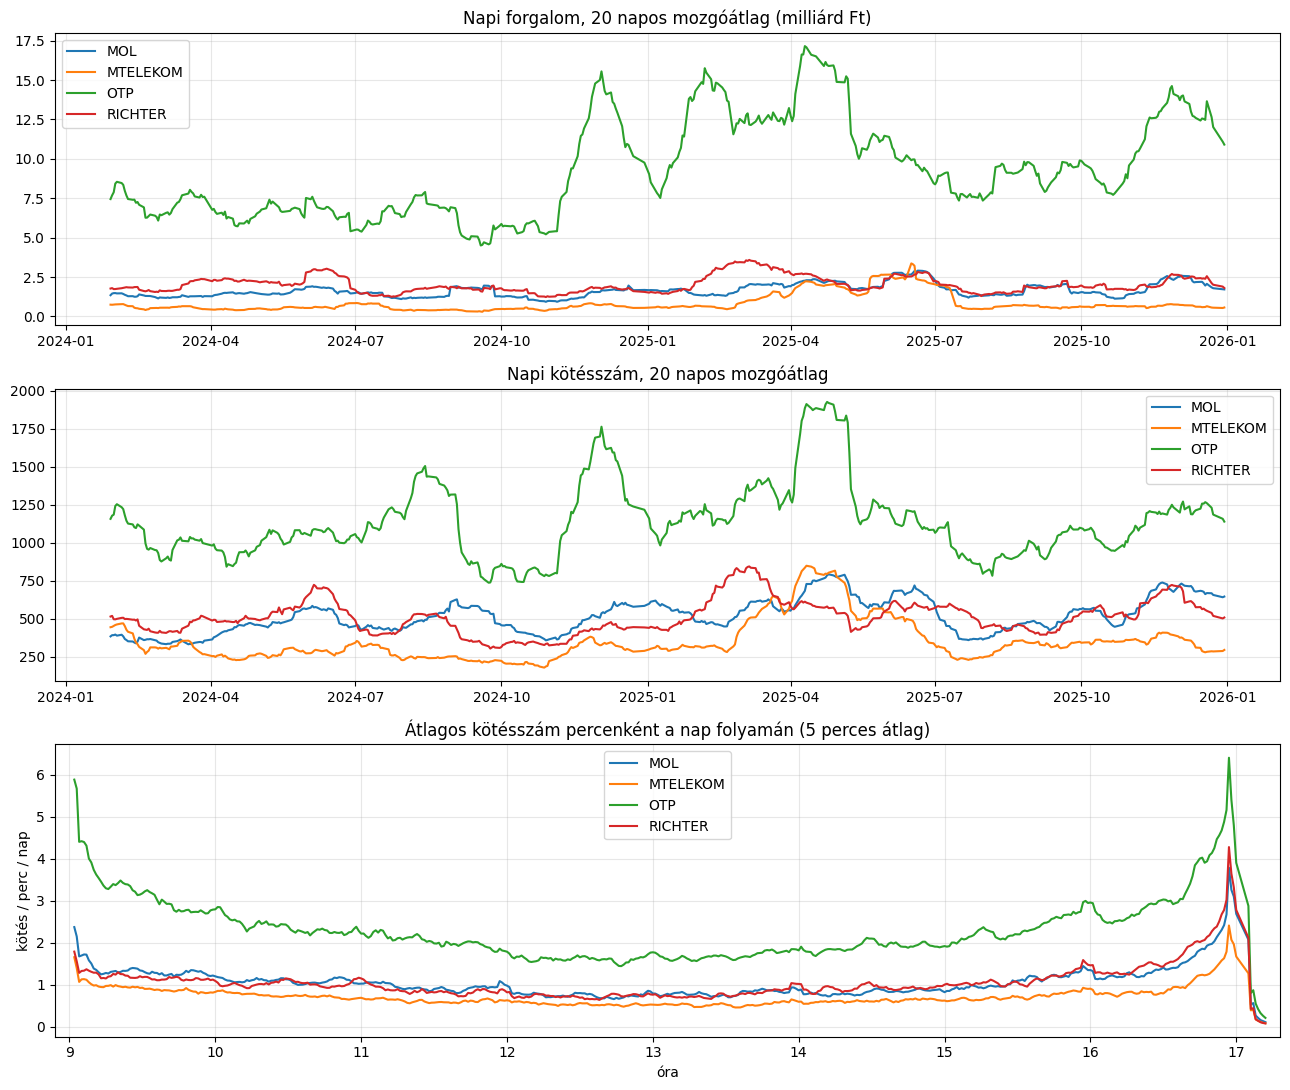

In [4]:
napi = kotes.groupby(["ticker", "nap"]).agg(db=("ar", "size"), ertek=("ertek", "sum")).reset_index()
napi["nap"] = pd.to_datetime(napi.nap)
fig, ax = plt.subplots(3, 1, figsize=(13, 11))
for ticker, g in napi.groupby("ticker"):
    g = g.set_index("nap")
    ax[0].plot((g.ertek / 1e9).rolling(20).mean(), label=ticker)
    ax[1].plot(g.db.rolling(20).mean(), label=ticker)
percenkent = kotes.groupby(["ticker", "perc"]).size().unstack(0).fillna(0) / D
for ticker in tickerek:
    ax[2].plot(percenkent.index / 60, percenkent[ticker].rolling(5, center=True).mean(), label=ticker)
ax[0].set_title("Napi forgalom, 20 napos mozgóátlag (milliárd Ft)")
ax[1].set_title("Napi kötésszám, 20 napos mozgóátlag")
ax[2].set_title("Átlagos kötésszám percenként a nap folyamán (5 perces átlag)")
ax[2].set_xlabel("óra")
ax[2].set_ylabel("kötés / perc / nap")
ax[2].set_xlim(8.9, 17.3)
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()

A négy papírra 1 241 650 kötés jutott. A forgalom 67%-a (4 585 milliárd Ft a 6 799 milliárdból) és a kötések 45%-a az OTP-é, a Magyar Telekom forgalma a legkisebb (406 milliárd Ft). A napi forgalom és kötésszám időben is erősen ingadozik. Napon belül a percenkénti kötésszám a nyitás után és a zárás előtt a legnagyobb, napközben a legkisebb, 17:00 után pedig a záró aukció kötései jelennek meg.

## 2. A perces rács

**Perces rács.** A hír hatását percekben mérem, mert a BÉT prémium papírjain az információ néhány perc alatt beépül az árba (Kovács, 2017), és egy napon belül ugyanarról a cégről több cikk is megjelenhet, amelyek hatása napi adaton nem választható szét (Groth & Muntermann, 2008). A kötések szabálytalan időpontokban történnek, ezért közös, szabályos időbeosztásra (rácsra) van szükség, amelyben minden nap minden percének van ára és forgalma.

A rács minden kereskedési napon a 09:00 és 17:00 közötti 481 percet tartalmazza. Ez a BÉT folyamatos kereskedési szakasza: a nyitó aukció 09:00-kor, legfeljebb 30 másodperces véletlen lezárással ér véget, a folyamatos kereskedés 17:00-ig tart ([BÉT, kereskedési idő](https://www.bet.hu/Befektetok/Kereskedes/Kereskedesi-ido)). A nyitó aukció kötései a 09:00-s percbe kerülnek. A 17:00 utáni záró aukció és az utána záróáron kötött ügyletek nem kerülnek a rácsba, a záró aukció árát csak a piaci súlyokhoz használom (3. szakasz).

- **Perc-ár:** az adott perc utolsó kötésének ára. Ha a percben nem volt kötés, az előző perc ára marad érvényben, a napok között is. Így a nap első percének (09:00) hozama az előző nap utolsó kötése óta történt változást, vagyis az éjszakai rést is tartalmazza.
- **Forgalom:** a percben kötött darabszámok összege, kötés nélküli percben 0.

In [5]:
racson_belul = kotes.perc.between(PERC_KEZDET, PERC_VEG)
print(f"A 09:00–17:00 közé eső kötések aránya: {racson_belul.mean():.1%}, "
      f"a forgalmazott darabszámé: {kotes.mennyiseg[racson_belul].sum() / kotes.mennyiseg.sum():.1%}")
kotes = kotes[racson_belul]

A 09:00–17:00 közé eső kötések aránya: 99.5%, a forgalmazott darabszámé: 74.1%


In [6]:
racs_index = pd.MultiIndex.from_product([napok, PERCEK], names=["nap", "perc"])
arfolyam = {}
V = {}
for ticker, resz in kotes.groupby("ticker"):
    percenkent = (resz.groupby(["nap", "perc"])
                  .agg(ar=("ar", "last"), mennyiseg=("mennyiseg", "sum"))
                  .reindex(racs_index))
    arfolyam[ticker] = percenkent.ar.ffill().to_numpy().reshape(D, N)
    V[ticker] = percenkent.mennyiseg.fillna(0).to_numpy().reshape(D, N)

print(f"A rács mérete papíronként: {D} nap × {N} perc")
print("A kötés nélküli percek aránya:")
for ticker in tickerek:
    print(f"  {ticker}: {(V[ticker] == 0).mean():.1%}")

A rács mérete papíronként: 495 nap × 481 perc
A kötés nélküli percek aránya:
  MOL: 56.8%
  MTELEKOM: 65.6%
  OTP: 36.7%
  RICHTER: 58.4%


A 495 kereskedési nap 1 241 650 kötésének 99,5%-a esik a 09:00–17:00 közötti időbe, a forgalmazott darabszámnak viszont csak 74,1%-a: a darabszám negyede a 17:00 utáni záró aukcióban és az utána záróáron kötött ügyletekben forog, ez a rácsba nem kerül be. A percek 36,7% (OTP) és 65,6% (Magyar Telekom) közötti részében nem volt kötés; ezekben a percekben az előző árat használom, a hozam pedig marad 0.

## 3. A piaci hozam súlyai

**A piaci hozam a másik három papírból.** A négy vizsgált papír (OTP, MOL, Richter, Magyar Telekom) adja a BUX nagy részét. Ha a vizsgált papír hozamából a BUX hozamát vonnám le, a papír saját mozgásának egy részét is kivonnám, és ez torzítaná az abnormális hozamot. Ezért az $i$-edik papír piaci hozama a másik három vizsgált papír súlyozott hozama.
A súly a BUX súlyozását követi: a papír indexbe számított darabszáma ($Q$), közkézhányada ($FF$) és súlyozási tényezője ($WF$) szorozva az előző napi záróárral ($P_{j,d-1}$), a másik három papírra normálva:

$$w_{j,d}=\frac{Q_j\,FF_j\,WF_j\,P_{j,d-1}}{\sum_{k\neq i} Q_k\,FF_k\,WF_k\,P_{k,d-1}}$$

A $Q$, $FF$ és $WF$ értékét a BÉT indexkosár-közleményeiből veszem, mindig az adott napon érvényes kosárból. A súly a nap folyamán állandó. A záróár a nap utolsó kötésének ára, vagyis a záró aukció ára. Az első kereskedési napnak nincs előző napi záróára, ezért erre a napra nincs piaci hozam; ez a nap a bázis hiánya miatt amúgy sem kerül az események közé.

In [7]:
kosar = pd.read_csv(PROJEKT / "bux_kosar.csv", sep=";")
kosar["Q_FF_WF"] = kosar.Q * kosar.FF * kosar.WF
display(kosar[["ervenyes_tol", "hivatkozasi_nap", "ticker", "Q", "FF", "WF", "suly_kosarban_pct"]])

kosar_napi = kosar.pivot(index="ervenyes_tol", columns="ticker", values="Q_FF_WF")
kosar_napi = kosar_napi.reindex(kosar_napi.index.union(napok)).ffill().loc[napok]
piaci_ertek = kosar_napi * zaroar.shift(1)

negy_papir_suly = piaci_ertek.div(piaci_ertek.sum(axis=1), axis=0)
print("A súlyok átlaga a négy papírra normálva (%):")
print((100 * negy_papir_suly.mean()).round(1).to_string())

,ervenyes_tol,hivatkozasi_nap,ticker,Q,FF,WF,suly_kosarban_pct
0,2023-03-20,2023-03-01,MOL,819424824,0.6156,0.639302,27.3874
1,2023-03-20,2023-03-01,MTELEKOM,1005801352,0.3861,1.000000,4.7635
2,2023-03-20,2023-03-01,OTP,280000010,0.8633,0.455296,36.9866
3,2023-03-20,2023-03-01,RICHTER,186374860,0.6968,0.770534,23.7504
4,2024-03-18,2024-03-01,MOL,819424824,0.6156,0.756708,24.4334
5,2024-03-18,2024-03-01,MTELEKOM,971558867,0.3645,1.000000,6.5308
6,2024-03-18,2024-03-01,OTP,280000010,0.8634,0.429890,39.6164
7,2024-03-18,2024-03-01,RICHTER,186374860,0.6968,0.803127,21.9611
8,2024-09-23,2024-09-02,MOL,819424824,0.6156,0.793336,22.3750
9,2024-09-23,2024-09-02,MTELEKOM,938617497,0.3422,1.000000,6.9009


A súlyok átlaga a négy papírra normálva (%):
ticker
MOL         23.0
MTELEKOM     8.6
OTP         46.6
RICHTER     21.8


**Ellenőrzés.** Ha a súlyokat jól számolom, a BÉT által közölt kosárbeli súlyokat kell visszakapnom. A közölt súlyok a teljes BUX-kosárra vonatkoznak, ezért a saját és a közölt súlyt is a négy papírra normálom, és a kosár hivatkozási napjának záróárával számolok. Csak azokat a kosarakat tudom ellenőrizni, amelyek hivatkozási napja a vizsgált időszakba esik.

In [8]:
ellenorzes = []
for (ervenyes_tol, hivatkozasi_nap), k in kosar.groupby(["ervenyes_tol", "hivatkozasi_nap"]):
    if hivatkozasi_nap not in zaroar.index:
        continue
    k = k.set_index("ticker")
    sajat = k.Q_FF_WF * zaroar.loc[hivatkozasi_nap]
    ellenorzes.append(pd.DataFrame({
        "ervenyes_tol": ervenyes_tol,
        "sajat_%": 100 * sajat / sajat.sum(),
        "BET_%": 100 * k.suly_kosarban_pct / k.suly_kosarban_pct.sum(),
    }))
ellenorzes = pd.concat(ellenorzes)
ellenorzes["elteres_szazalekpont"] = ellenorzes["sajat_%"] - ellenorzes["BET_%"]
display(ellenorzes.round(4))
print(f"{len(ellenorzes)} összehasonlítás, a legnagyobb eltérés: "
      f"{ellenorzes.elteres_szazalekpont.abs().max():.5f} százalékpont")

,ervenyes_tol,sajat_%,BET_%,elteres_szazalekpont
ticker,,,,
MOL,2024-03-18,26.4026,26.4026,0.0000
MTELEKOM,2024-03-18,7.0572,7.0571,0.0000
OTP,2024-03-18,42.8092,42.8092,-0.0001
RICHTER,2024-03-18,23.7311,23.7310,0.0000
MOL,2024-09-23,24.3374,24.3374,-0.0000
MTELEKOM,2024-09-23,7.5061,7.5061,-0.0001
OTP,2024-09-23,43.3475,43.3475,0.0000
RICHTER,2024-09-23,24.8090,24.8090,0.0000
MOL,2025-04-01,22.5959,22.5959,0.0000


16 összehasonlítás, a legnagyobb eltérés: 0.00008 százalékpont


A súlyok átlaga a négy papírra normálva: OTP 46,6%, MOL 23,0%, Richter 21,8%, Magyar Telekom 8,6%. A saját súlyok a BÉT által közölt súlyokkal mind a 16 összehasonlításban egyeznek, a legnagyobb eltérés 0,0001 százalékpont.

## 4. Hozam, piaci hozam, abnormális hozam

**Loghozam.** Az eseménytanulmányban egymást követő percek hozamait adom össze egy ablakra. A loghozam időben összeadható: a percek loghozamainak összege az egész időszak loghozama. Szimmetrikus is: ha az ár az egyik percben 100-ról 110-re nő, a következőben visszaesik 100-ra, a két loghozam összege pontosan 0. 

**Piaccal kiigazított modell.** Az abnormális hozam a tényleges hozam és a piaci mozgás alapján várt hozam különbsége: ha egy papír 5%-ot emelkedik, de a piaci mozgás alapján 2% volt várható, az abnormális hozam 3 százalékpont. Klein és Rosenfeld (1987) szerint a piaccal kiigazított modell az egytényezős indexmodellhez hasonló eredményt ad.

A papír hozamából közvetlenül kivonom a piaci hozamot:

$$R_{i,t}=\ln\frac{P_{i,t}}{P_{i,t-1}}, \qquad R_{m,t}=\sum_{j\neq i} w_{j,d}\,R_{j,t}, \qquad AR_{i,t}=R_{i,t}-R_{m,t}$$

In [9]:
R = {}
for ticker in tickerek:
    log_ar = np.log(arfolyam[ticker].ravel())
    R[ticker] = np.diff(log_ar, prepend=np.nan).reshape(D, N)

R_m = {}
AR = {}
for ticker in tickerek:
    tobbi = [j for j in tickerek if j != ticker]
    w = piaci_ertek[tobbi].div(piaci_ertek[tobbi].sum(axis=1), axis=0)
    R_m[ticker] = sum(w[j].to_numpy()[:, None] * R[j] for j in tobbi)
    AR[ticker] = R[ticker] - R_m[ticker]

**A piaci hozam ellenőrzése.** Ha a papír hozama és a piaci hozam közti korreláció kicsi, a levont piaci hozam főleg zajt ad hozzá, és az AR szórása nagyobb lesz a hozaménál.

In [10]:
sorok = []
for ticker in tickerek:
    r, rm, ar = R[ticker].ravel(), R_m[ticker].ravel(), AR[ticker].ravel()
    van = ~np.isnan(r) & ~np.isnan(rm)
    sorok.append({
        "ticker": ticker,
        "R szórása (bp)": BP * r[van].std(),
        "AR szórása (bp)": BP * ar[van].std(),
        "az AR szórása ennyivel nagyobb (%)": 100 * (ar[van].std() / r[van].std() - 1),
        "korreláció (R, R_m)": np.corrcoef(r[van], rm[van])[0, 1],
    })
display(pd.DataFrame(sorok).set_index("ticker").round(3))

,R szórása (bp),AR szórása (bp),az AR szórása ennyivel nagyobb (%),"korreláció (R, R_m)"
ticker,,,,
MOL,9.524,11.100,16.551,0.069
MTELEKOM,12.239,13.283,8.530,0.055
OTP,8.852,10.520,18.846,0.076
RICHTER,10.263,11.710,14.098,0.059


A hozam és a mesterséges piac korrelációja papíronként 0,055 és 0,076 között van, ezért az AR szórása 8,5–18,8%-kal nagyobb a hozaménál (például az OTP-nél 8,85 bp helyett 10,52 bp). A hozam és a mesterséges piac (a másik három papír súlyozott hozama) korrelációja viszont csak 0,055–0,076, vagyis a piaci komponens a papír egyperces mozgásából alig magyaráz valamit (a korreláció négyzete, tehát a megmagyarázott variancia, mindössze 0,3–0,7%).

## 5. Bázissal korrigált abszolút abnormális hozam, abnormális forgalom

**Abszolút érték.** A híreket nem sorolom előre jó és rossz hírekre, és egy hír emelheti és csökkentheti is az árfolyamot. Átlagoláskor a pozitív és a negatív AR kioltaná egymást, ezért a kilengés nagyságát mérem, az irányát nem:

$$AAR_{i,t}=\lvert AR_{i,t}\rvert$$

**Bázis.** Az abszolút érték sosem negatív, ezért az átlaga hír nélkül is nagyobb lenne nullánál, és a nullhipotézist szinte biztosan elvetném. Muntermann és Güttler (2005) nyomán ezért a hír nélküli időszak átlagos kilengését kivonom az eseménykori kilengésből. A bázist percenként, az azonos napszakra számolom, mert a napon belüli ingadozás és forgalom U alakú, a nyitás és a zárás körül a legnagyobb (lásd az ábrát). Egyetlen napi átlaghoz viszonyítva a nyitás vagy a zárás körüli híreket mindig nagy hatásúnak látnám.

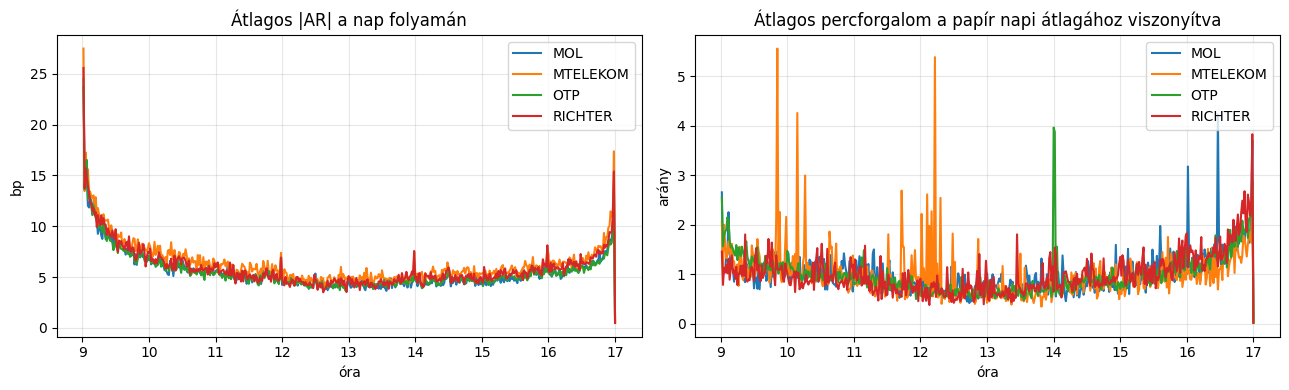

Az átlagos |AR| a 09:00-s percben (bp): {'MOL': 44.3, 'MTELEKOM': 46.3, 'OTP': 42.5, 'RICHTER': 44.7}


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for ticker in tickerek:
    ax[0].plot(PERCEK[1:] / 60, BP * np.nanmean(np.abs(AR[ticker]), axis=0)[1:], label=ticker)
    ax[1].plot(PERCEK[1:] / 60, (V[ticker].mean(axis=0) / V[ticker].mean())[1:], label=ticker)
ax[0].set_title("Átlagos |AR| a nap folyamán")
ax[0].set_ylabel("bp")
ax[1].set_title("Átlagos percforgalom a papír napi átlagához viszonyítva")
ax[1].set_ylabel("arány")
for a in ax:
    a.set_xlabel("óra")
    a.legend()
plt.tight_layout()
plt.show()
print("Az átlagos |AR| a 09:00-s percben (bp):",
      {ticker: round(float(BP * np.nanmean(np.abs(AR[ticker][:, 0]))), 1) for ticker in tickerek})

Az ábrán a 09:00-s perc nem szerepel, mert az éjszakai rés miatt sokszorosa a többi percnek (az értékét a cella alatt kiírom).

*A $t=(d,\tau)$ időpont ($d$: nap, $\tau$: a nap perce) bázisa az előző 20 kereskedési nap azonos percének átlaga. A hírt közvetlenül megelőző napot ($d-1$) kihagyom, mert a kereskedést a hírre való várakozás már befolyásolhatja, így a bázis a $d-21\dots d-2$ napokból áll:

$$\overline{AAR}_{i,\tau,d}=\frac{1}{20}\sum_{k=2}^{21}AAR_{i,\tau,d-k}, \qquad CAAR_{i,t}=AAR_{i,t}-\overline{AAR}_{i,\tau,d}$$

A $CAAR_{i,t}$ azt mutatja, mennyivel haladja meg a kilengés a hír nélküli időszakokra ugyanabban a percben jellemző szintet.

**Abnormális forgalom.** Ugyanezt a logikát követi, ugyanazzal a bázissal:

$$\overline{V}_{i,\tau,d}=\frac{1}{20}\sum_{k=2}^{21}V_{i,\tau,d-k}, \qquad AV_{i,t}=V_{i,t}-\overline{V}_{i,\tau,d}$$

Az első 21 kereskedési napnak nincs teljes bázisa, ezekre a napokra a korrigált mutatók üresek (NaN), az ilyen napokra eső eseményeket később kihagyom.

In [12]:
def bazis(X):
    eredmeny = np.full(X.shape, np.nan)
    for d in range(BAZIS_NAPOK + KIHAGYOTT_NAP, X.shape[0]):
        eredmeny[d] = np.nanmean(X[d - BAZIS_NAPOK - KIHAGYOTT_NAP:d - KIHAGYOTT_NAP], axis=0)
    return eredmeny


tablak = []
for ticker in tickerek:
    aar = np.abs(AR[ticker])
    aar_bazis = bazis(aar)
    v_bazis = bazis(V[ticker])
    abs_r = np.abs(R[ticker])
    tablak.append(pd.DataFrame({
        "ticker": ticker,
        "nap": np.repeat(napok, N),
        "perc": np.tile(PERCEK, D),
        "V": V[ticker].ravel(),
        "R": R[ticker].ravel(),
        "R_m": R_m[ticker].ravel(),
        "AR": AR[ticker].ravel(),
        "AAR": aar.ravel(),
        "AAR_bazis": aar_bazis.ravel(),
        "CAAR": (aar - aar_bazis).ravel(),
        "V_bazis": v_bazis.ravel(),
        "AV": (V[ticker] - v_bazis).ravel(),
        "R_kor": (abs_r - bazis(abs_r)).ravel(),
    }))
perc = pd.concat(tablak, ignore_index=True)

print(f"{len(perc):,} sor = {D} nap × {N} perc × {len(tickerek)} papír")
print(f"Bázis nélküli sorok aránya: {perc.CAAR.isna().mean():.1%}")
print("A CAAR átlaga papíronként (bp):", (BP * perc.groupby("ticker").CAAR.mean()).round(3).to_dict())

952,380 sor = 495 nap × 481 perc × 4 papír
Bázis nélküli sorok aránya: 4.2%
A CAAR átlaga papíronként (bp): {'MOL': -0.011, 'MTELEKOM': -0.084, 'OTP': -0.043, 'RICHTER': -0.038}


Az ábrán látszik az U alak: az átlagos |AR| a nyitás utáni percekben 10–25 bp, napközben 4–5 bp, a zárás előtt ismét nő, és a forgalom is a nap két végén a legnagyobb. A 09:00-s perc átlagos |AR|-ja 42–46 bp (az éjszakai rés). A 17:00-s percben alig van kötés, mert a folyamatos kereskedés 17:00:00-kor ér véget, ezért ott az |AR| és a forgalom közel nulla. A sorok 4,2%-ának nincs bázisa (az első 21 kereskedési nap). A CAAR átlaga papíronként −0,08 és −0,01 bp között van, vagyis a bázis levonása után a mutató átlagosan nulla körül mozog.

## 6. Mentés

A `perc_idosor.parquet` oszlopai (a hozamok loghozamban, a forgalom darabban; a bázispontba váltás a 03. notebookban történik):

| oszlop | jelentése |
|---|---|
| `V`, `V_bazis`, `AV` | forgalom, a bázisa, abnormális forgalom |
| `R`, `R_m`, `AR` | loghozam, piaci hozam, abnormális hozam |
| `AAR`, `AAR_bazis`, `CAAR` | abszolút abnormális hozam, a bázisa, a kettő különbsége |
| `R_kor` | a nem kiigazított abszolút hozam mínusz a bázisa |

In [13]:
perc.to_parquet(CACHE / "perc_idosor.parquet", index=False)
print("Elmentve: perc_idosor.parquet")

Elmentve: perc_idosor.parquet
